# From emitted photons to measured signals

A simulated emission is not automatically a detected photon. Optical routing,
wavelength selection, detection efficiency, binning, and noise shape the
signal. Here one blinking dye supplies photons to two spectral channels, then
we extract blinking and correlation statistics from the measured counts.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fluopy import blinking as bl
from fluopy import emissions as em
from fluopy import fcs
from fluopy import fluo_data as fd
from fluopy import fluorophores as fl
from fluopy import simulation as si
from fluopy import transitions as tr

## Make a blinking photon source

To keep switching visible in a short acquisition, we use illustrative
excitation, emission, shelving, and recovery rates with the bundled Cy5
emission spectrum. These rates are not the built-in Cy5 kinetic model.
The dark state is T1 in this simple three-state example.

In [14]:
dye = fl.Fluorophore("blinking_dye", [0, 0], constants=fd.cy5_dna)
system = fl.FluorophoreSystem([dye])
transitions = {
    dye.name: [
        tr.Transition(tr.TransitionType.EXCITATION, 1e5, [0]),
        tr.Transition(tr.TransitionType.FLUORESCENT_EMISSION, 1e6, [0]),
        tr.Transition(tr.TransitionType.INTERSYSTEM_CROSSING_ST, 2e3, [0]),
        tr.Transition(tr.TransitionType.INTERSYSTEM_CROSSING_TS, 50, [0]),
    ]
}
model = tr.TransitionSet(transitions, system)
simulation = si.Simulation(model)
simulation.run(size=10_000, end_time=2, seed=31, warn_precision=False)

## Collect two spectral channels

bandpass selects wavelengths in nm; detection_efficiency describes detection
losses. The two channels below record 650-680 nm and 680-750 nm light from the
same dye. Each emitted photon can be detected in at most one channel.
Overlapping bandpasses are illustrated in the beamsplitter example below.

The plot shows the first 0.3 s, with each step representing the counts in one
1 ms frame.

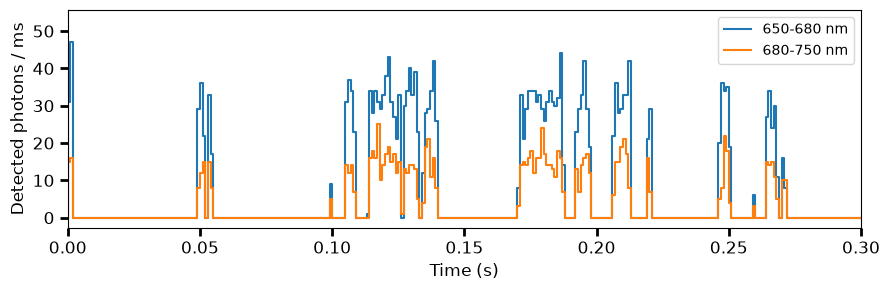

In [16]:
channels = {
    "650-680 nm": em.DetectionChannel((650, 680), detection_efficiency=0.7),
    "680-750 nm": em.DetectionChannel((680, 750), detection_efficiency=0.5),
}
detected = em.Emissions(frame_time="1ms", channels=channels, seed=32)
detected.extract(simulation)
fig, ax = plt.subplots(figsize=(9, 3))
for index, name in enumerate(channels):
    detected.plot_time_series(
        channel=name,
        ax=ax,
        type_="step",
        where="pre",
        color=f"C{index}",
        label=name,
        xlim=(0, 0.3),
        ylabel="Detected photons / ms",
        fontsize=12,
        legend=True,
        legendargs={"fontsize": 10},
    )
fig.tight_layout()

## Simulate detected photons directly

Emissions.extract() retains access to the full Simulation trajectory.
Emissions.simulate() instead generates the detected photons and counts
without retaining the full hidden-state trajectory. Here frames determines
acquisition duration, and size controls the random-number batch size.
store_time_points=True also retains photon arrival times for later analysis.
Independent acquisitions fluctuate and are not expected to match count by count.

In [17]:
direct = em.Emissions(frame_time="1ms", channels=channels, seed=33)
direct.simulate(model, frames=2_000, size=10_000, store_time_points=True)
pd.DataFrame(
    {
        "extracted_total_counts": detected.event_time_series.sum(),
        "direct_total_counts": direct.event_time_series.sum(),
    }
)

,extracted_total_counts,direct_total_counts
650-680 nm,18986,15631
680-750 nm,8503,7046


## Optional: split the same wavelength band between detectors

Overlapping passbands can represent distinct optical paths when routing
probabilities partition the light. These two channels sit behind a 50/50
splitter. Scalar or Spectrum responses can also represent filter transmission
and wavelength-dependent detection efficiency. The optical responses of paths
collecting from the same emitter must sum to at most one at each wavelength,
before detection losses are applied.

In [18]:
split_channels = {
    "left": em.DetectionChannel((650, 750), routing_probability=0.5),
    "right": em.DetectionChannel((650, 750), routing_probability=0.5),
}
split = em.Emissions(frame_time="1ms", channels=split_channels, seed=34)
split.extract(simulation)
split.event_time_series.sum().rename("Detected photons")

left     22215
right    22135
Name: Detected photons, dtype: int64

## Add noise

Poisson noise changes frame counts while leaving the stored emission
arrival times unchanged. Do time-point analyses on the event data and
count-based analyses on the modified trace with that distinction in mind.
Fluopy also provides Gaussian noise and EMCCD gain methods.

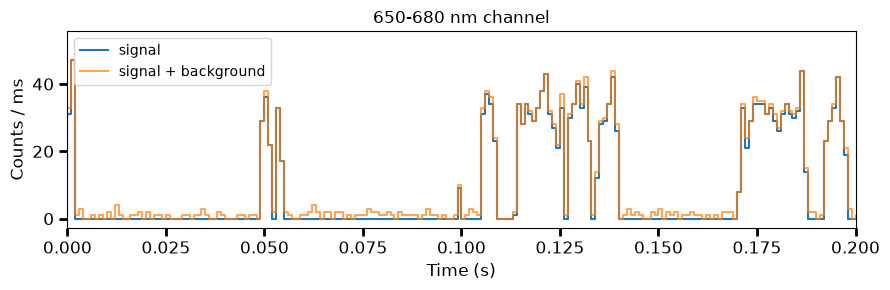

In [19]:
noisy = em.Emissions(frame_time="1ms", channels=channels, seed=32)
noisy.extract(simulation)
noisy.add_poisson_noise(rate={"650-680 nm": 1.0, "680-750 nm": 2.0})
fig, ax = plt.subplots(figsize=(9, 3))
detected.plot_time_series(
    channel="650-680 nm",
    ax=ax,
    type_="step",
    where="pre",
    color="C0",
    label="signal",
    xlim=(0, 0.2),
    ylabel="Counts / ms",
    fontsize=12,
    legend=True,
    legendargs={"fontsize": 10},
)
noisy.plot_time_series(
    channel="650-680 nm",
    ax=ax,
    type_="step",
    where="pre",
    color="C1",
    label="signal + background",
    alpha=0.7,
    xlim=(0, 0.2),
    ylabel="Counts / ms",
    fontsize=12,
    legend=True,
    legendargs={"fontsize": 10},
)
ax.set_title("650-680 nm channel")
fig.tight_layout()

## Read switching from the observed signal

Blinking uses an explicit channel and count threshold. Frames at or below
threshold are OFF; memory allows short OFF gaps inside ON periods. Period
arrays are in frames, so convert to seconds with the frame duration. These
are thresholded signal statistics, not direct measurements of hidden-state
residence times. Binning, losses, background, and threshold change the result.

In [20]:
blinking = bl.Blinking(detected, channel="650-680 nm", threshold=2, memory=1)
pd.Series(
    {
        "Number ON periods": blinking.on_periods.size,
        "Number OFF periods": blinking.off_periods.size,
        "median ON duration (ms)": np.median(blinking.on_periods),
        "median OFF duration (ms)": np.median(blinking.off_periods),
    }
)

Number ON periods           73.0
Number OFF periods          72.0
median ON duration (ms)      6.0
median OFF duration (ms)    15.5
dtype: float64

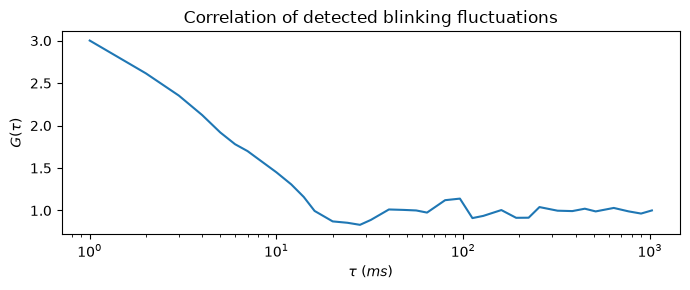

In [21]:
correlation = fcs.FCS(detected, channel="650-680 nm")
correlation.autocorrelate_time_series(m=8)
fig, ax = plt.subplots(figsize=(7, 3))
correlation.plot_matplotlib(unit="ms", ax=ax)
ax.set_title("Correlation of detected blinking fluctuations")
fig.tight_layout()

The smallest time-series correlation lag is the frame duration. Fluopy can
also correlate stored photon arrival times with autocorrelate_time_points().

By default, autocorrelate_time_points() assumes that the measurement ended
when the last photon in the selected channel arrived. For example, if a
2 s acquisition has its last photon at 1.9 s, the default leaves out the
remaining 0.1 s with no detections. Passing end_time=2 includes that interval
when calculating the average count rate used to normalize the correlation.
Use the actual acquisition end time when it is known.

## Optional: derive dSTORM chemistry from bundled data

A buffer-dependent model can be generated with dstorm=True. Here concentration
is in mM, irradiance in kW/cm², and wavelength in nm. Inspect the added
transitions before selecting acquisition duration: slow dark-state recovery
can require much longer observations than the illustrative source above.

In [22]:
cy5 = fl.Fluorophore("cy5_dna", [0, 0])
dstorm_system = fl.FluorophoreSystem([cy5])
dstorm_transitions = dstorm_system.load_transitions(
    wavelength=640,
    irradiance=2,
    energy_transfer=False,
    bleaching=False,
    dstorm=True,
    dstorm_parameters={"reducing_agent": "mea", "concentration": 100, "ph": 8},
)
dstorm_model = tr.TransitionSet(dstorm_transitions, dstorm_system)
dstorm_model.transition_df[["abbreviation", "initial_state", "final_state", "rate"]]

abbreviation                     initial_state  \
Fluorophore identity                                                  
cy5_dna     0                 EXC   SingleState(name='S0', value=0)   
            1                 FLU   SingleState(name='S1', value=1)   
            2              ISC_ST   SingleState(name='S1', value=1)   
            3              ISC_TS   SingleState(name='T1', value=3)   
            4                 ISO   SingleState(name='S1', value=1)   
            5               PBISO  SingleState(name='cis', value=6)   
            6               TBISO  SingleState(name='cis', value=6)   
            7                  IC   SingleState(name='S1', value=1)   
            8              PET_TS   SingleState(name='T1', value=3)   
            9              PET_SS   SingleState(name='S1', value=1)   
            10             PET_TO   SingleState(name='T1', value=3)   
            11             PET_SO   SingleState(name='S1', value=1)   
            12                 PU  SingleState(name='OFF', value=7)   
            13                 TE  SingleState(name='OFF', value=7)   
            14             PET_TR   SingleState(name='T1', value=3)   
            15                OXI    SingleState(name='R', value=9)   

                                           final_state          rate  
Fluorophore identity                                                  
cy5_dna     0          SingleState(name='S1', value=1)  5.815700e+06  
            1          SingleState(name='S0', value=0)  1.588235e+08  
            2          SingleState(name='T1', value=3)  8.300000e+05  
            3          SingleState(name='S0', value=0)  5.000000e+03  
            4         SingleState(name='cis', value=6)  4.000000e+06  
            5          SingleState(name='S0', value=0)  3.866202e+04  
            6          SingleState(name='S0', value=0)  5.000000e+03  
            7          SingleState(name='S0', value=0)  4.245818e+08  
            8          SingleState(name='S0', value=0)  9.090909e+05  
            9          SingleState(name='S0', value=0)  9.090909e+06  
            10        SingleState(name='OFF', value=7)  9.090909e+02  
            11        SingleState(name='OFF', value=7)  9.090909e+03  
            12         SingleState(name='S0', value=0)  3.866202e-02  
            13         SingleState(name='S0', value=0)  1.000000e-02  
            14          SingleState(name='R', value=9)  9.090909e+03  
            15         SingleState(name='S0', value=0)  1.300000e+03

Next: [Pulsed excitation and TCSPC](04_TCSPC.ipynb). For custom spectra and
kinetics, see [Extending Fluopy](Tutorial_extending_fluopy.ipynb).